# Explore predicted fluxes

QC of the mechanistic flux layer: distributions, FB vs iFB shifts, and the
Responder vs Non-Responder contrast. Run the pipeline first:

```bash
python -m gems.pipeline --raw data/raw --crosswalk data/maps/gse140669_symbol_to_entrez.tsv
```

In [1]:
# Make `gems` importable whether or not it's pip-installed in this kernel.
# (Best: run Jupyter from the project venv — see README.)
import sys, pathlib
for _c in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (_c / 'src' / 'gems').is_dir():
        sys.path.insert(0, str(_c / 'src')); break
else:
    raise RuntimeError('Could not locate src/gems — run this notebook from inside the gems repo.')

In [2]:
import pandas as pd
from gems import config as C

ft = pd.read_csv(C.FLUX_DIR / 'flux_table.csv')
print(ft.shape)
ft.head()

(22032, 8)


,project,clone,condition,timepoint,responder,reaction_id,subsystem,flux
0,GSE140669,3068,FB,0,NaN,biomass_cho_s,BIOMASS,3.752308
1,GSE140669,3068,FB,0,NaN,ACITL,CITRIC ACID CYCLE,8.629008
2,GSE140669,3068,FB,0,NaN,ACONTa,CITRIC ACID CYCLE,0.000000
3,GSE140669,3068,FB,0,NaN,ACONTam,CITRIC ACID CYCLE,-8.629008
4,GSE140669,3068,FB,0,NaN,ACONTb,CITRIC ACID CYCLE,98.851197


In [3]:
# mean |flux| per subsystem, split by condition (or by timepoint if only one condition)
ft['absflux'] = ft['flux'].abs()
by = 'condition' if ft['condition'].nunique() > 1 else 'timepoint'
(ft.groupby(['subsystem', by])['absflux'].mean().unstack(by).round(3))

timepoint,0,4,7
subsystem,,,
BIOMASS,3.752,3.752,3.752
CITRIC ACID CYCLE,17.370,17.626,17.469
EXTRACELLULAR EXCHANGE,9.885,10.391,9.955
FATTY ACID METABOLISM,0.017,0.025,0.021
GLUTAMATE METABOLISM,3.603,3.917,4.018
GLYCEROLIPID METABOLISM,0.030,0.032,0.015
GLYCEROPHOSPHOLIPID METABOLISM,0.438,0.487,0.491
GLYCOLYSIS/GLUCONEOGENESIS,7.694,8.259,8.163
OXIDATIVE PHOSPHORYLATION,40.973,40.072,39.877


In [4]:
# lactate exchange trajectory (negative = uptake)
lac = ft[ft['reaction_id'] == C.METABOLITE_EXCHANGE['Lac']]
keys = [k for k in ['responder', 'condition'] if k in lac and lac[k].notna().any()] or ['clone']
lac.groupby(keys + ['timepoint'])['flux'].mean().unstack('timepoint').round(3)

timepoint,0,4,7
condition,,,
FB,0.0,0.0,0.0


In [5]:
# figures written by the pipeline run
sorted(p.name for p in C.FIG_DIR.glob('*.png'))

['diff_subsystem_7_vs_0.png',
 'diff_subsystem_7_vs_4.png',
 'diff_top_7_vs_0.png',
 'diff_top_7_vs_4.png',
 'diff_volcano_7_vs_0.png',
 'diff_volcano_7_vs_4.png',
 'flux_subsystem_heatmap.png',
 'flux_trajectories.png']

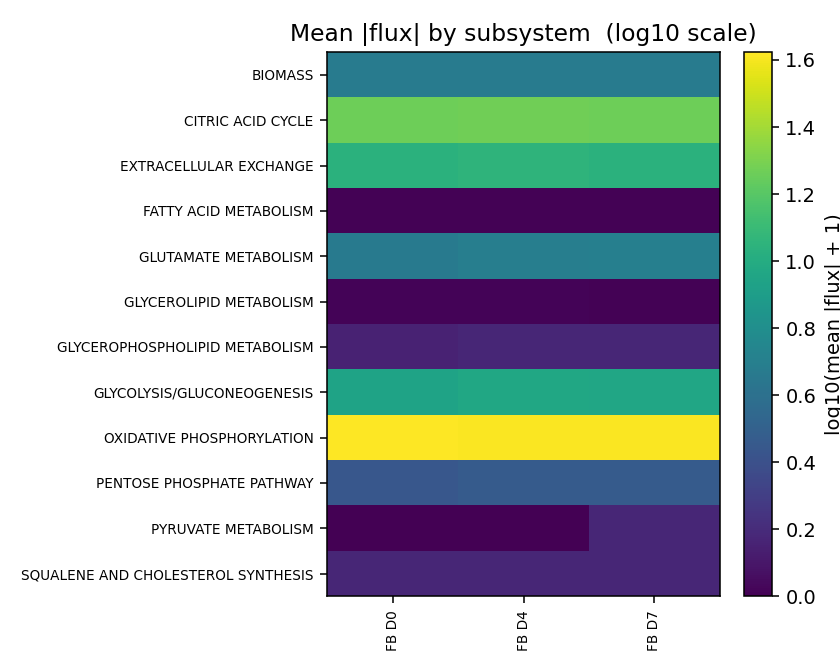

In [6]:
from IPython.display import Image
Image(str(C.FIG_DIR / 'flux_subsystem_heatmap.png'))